In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import warnings
warnings.filterwarnings("ignore")

In [31]:
df = pd.read_table("furnace_energy_data.csv", sep =",")

In [32]:
df

,batch_id,furnace_temp_C,soak_time_min,batch_weight_kg,ambient_temp_C,humidity_pct,gas_flow_m3h,burner_pressure_bar,exhaust_temp_C,fan_speed_rpm,motor_current_A,machine_age_years,vibration_mm_s,operator_shift,coolant_temp_C,aux_sensor_1,aux_sensor_2,aux_sensor_3,energy_kWh
0,B1000,862.19,154.10,1482.22,26.60,54.58,12.80,5.02,466.52,1470.26,34.21,9,5.59,3,28.54,-0.77,-0.66,-0.21,2429.94
1,B1001,808.40,142.38,1281.21,26.25,52.01,10.01,2.61,451.71,1521.62,37.30,5,3.84,3,26.51,-0.77,-1.21,-0.17,1923.43
2,B1002,880.02,102.01,1375.66,37.95,65.21,13.85,6.07,479.82,1471.87,34.39,2,3.26,2,21.63,1.01,-0.53,-1.33,2163.55
3,B1003,887.62,82.44,1690.17,31.98,63.02,14.05,5.18,472.29,1629.11,39.22,7,2.30,2,30.77,-0.42,0.34,-0.20,2319.32
4,B1004,771.96,45.89,1500.90,28.73,43.14,8.52,1.14,428.35,1564.38,36.73,4,2.92,2,28.73,-1.09,-0.28,-1.26,1558.89
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,B1495,887.42,128.82,1168.80,32.35,86.53,13.60,5.27,475.27,1340.16,33.67,13,3.91,1,33.17,-1.22,-3.02,-0.85,2395.14
496,B1496,776.74,139.17,1596.84,31.82,58.53,7.91,1.03,435.60,1411.72,33.96,1,3.47,1,29.99,-1.09,-0.39,0.36,1779.34
497,B1497,836.58,123.03,1154.97,29.45,33.69,12.14,4.44,454.98,1277.81,32.18,5,3.52,2,26.32,0.40,0.34,0.15,2044.74
498,B1498,770.37,123.27,1713.59,26.82,53.42,8.31,0.97,422.77,1469.23,35.42,9,3.42,1,27.79,-1.11,0.47,-0.07,1864.71


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   batch_id             500 non-null    object 
 1   furnace_temp_C       500 non-null    float64
 2   soak_time_min        500 non-null    float64
 3   batch_weight_kg      500 non-null    float64
 4   ambient_temp_C       500 non-null    float64
 5   humidity_pct         500 non-null    float64
 6   gas_flow_m3h         500 non-null    float64
 7   burner_pressure_bar  500 non-null    float64
 8   exhaust_temp_C       500 non-null    float64
 9   fan_speed_rpm        500 non-null    float64
 10  motor_current_A      500 non-null    float64
 11  machine_age_years    500 non-null    int64  
 12  vibration_mm_s       500 non-null    float64
 13  operator_shift       500 non-null    int64  
 14  coolant_temp_C       500 non-null    float64
 15  aux_sensor_1         500 non-null    flo

In [34]:
# Drop both 'batch_id' (identifier) and 'energy_kWh' (the target) from features
x = df.drop(columns=['batch_id', 'energy_kWh'])
y = df['energy_kWh']

In [35]:
df=df.drop(columns=['batch_id'])

In [36]:
df = pd.get_dummies(df, columns=["operator_shift"], drop_first=True, dtype=int)

In [37]:
df

,furnace_temp_C,soak_time_min,batch_weight_kg,ambient_temp_C,humidity_pct,gas_flow_m3h,burner_pressure_bar,exhaust_temp_C,fan_speed_rpm,motor_current_A,machine_age_years,vibration_mm_s,coolant_temp_C,aux_sensor_1,aux_sensor_2,aux_sensor_3,energy_kWh,operator_shift_2,operator_shift_3
0,862.19,154.10,1482.22,26.60,54.58,12.80,5.02,466.52,1470.26,34.21,9,5.59,28.54,-0.77,-0.66,-0.21,2429.94,0,1
1,808.40,142.38,1281.21,26.25,52.01,10.01,2.61,451.71,1521.62,37.30,5,3.84,26.51,-0.77,-1.21,-0.17,1923.43,0,1
2,880.02,102.01,1375.66,37.95,65.21,13.85,6.07,479.82,1471.87,34.39,2,3.26,21.63,1.01,-0.53,-1.33,2163.55,1,0
3,887.62,82.44,1690.17,31.98,63.02,14.05,5.18,472.29,1629.11,39.22,7,2.30,30.77,-0.42,0.34,-0.20,2319.32,1,0
4,771.96,45.89,1500.90,28.73,43.14,8.52,1.14,428.35,1564.38,36.73,4,2.92,28.73,-1.09,-0.28,-1.26,1558.89,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,887.42,128.82,1168.80,32.35,86.53,13.60,5.27,475.27,1340.16,33.67,13,3.91,33.17,-1.22,-3.02,-0.85,2395.14,0,0
496,776.74,139.17,1596.84,31.82,58.53,7.91,1.03,435.60,1411.72,33.96,1,3.47,29.99,-1.09,-0.39,0.36,1779.34,0,0
497,836.58,123.03,1154.97,29.45,33.69,12.14,4.44,454.98,1277.81,32.18,5,3.52,26.32,0.40,0.34,0.15,2044.74,1,0
498,770.37,123.27,1713.59,26.82,53.42,8.31,0.97,422.77,1469.23,35.42,9,3.42,27.79,-1.11,0.47,-0.07,1864.71,0,0


In [38]:
from sklearn.model_selection import train_test_split
xtrain, xtest, ytrain,ytest = train_test_split(x,y,test_size=0.3, random_state=1)

#Scaling technique RObust

In [39]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()

xtrain_scaled = scaler.fit_transform(xtrain)
xtest_scaled = scaler.transform(xtest)




#Regularization


In [40]:
# x = df.iloc[:,:-1]
# y= df.iloc[:,-1]

In [41]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [42]:
lr.fit(xtrain, ytrain)
ypred = lr.predict(xtest)

In [43]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error

print(r2_score(ytest,ypred))

0.9785365944947957


In [44]:
train = lr.score(xtrain, ytrain)
test = lr.score(xtest,ytest)
print(f"train acc {train}")
print(f"test acc {test}")

train acc 0.9803764518077925
test acc 0.9785365944947957


In [45]:
from sklearn.linear_model import Lasso, Ridge
l2 = Ridge(alpha=50)

l2.fit(xtrain, ytrain)

train1 = l2.score(xtrain, ytrain)
test1 = l2.score(xtest, ytest)
print(f"train acc {train1}")
print(f"test acc {test1}")

train acc 0.979929017955324
test acc 0.9794069185345983


In [46]:
l1 = Lasso(alpha=100)
# Note: Lasso typically requires a higher alpha on unscaled data
l1.fit(xtrain, ytrain)

train2 = l1.score(xtrain, ytrain)
test2 = l1.score(xtest, ytest)
print(f"train acc {train2}")
print(f"test acc {test2}")

train acc 0.9666205827434541
test acc 0.9700739427925424


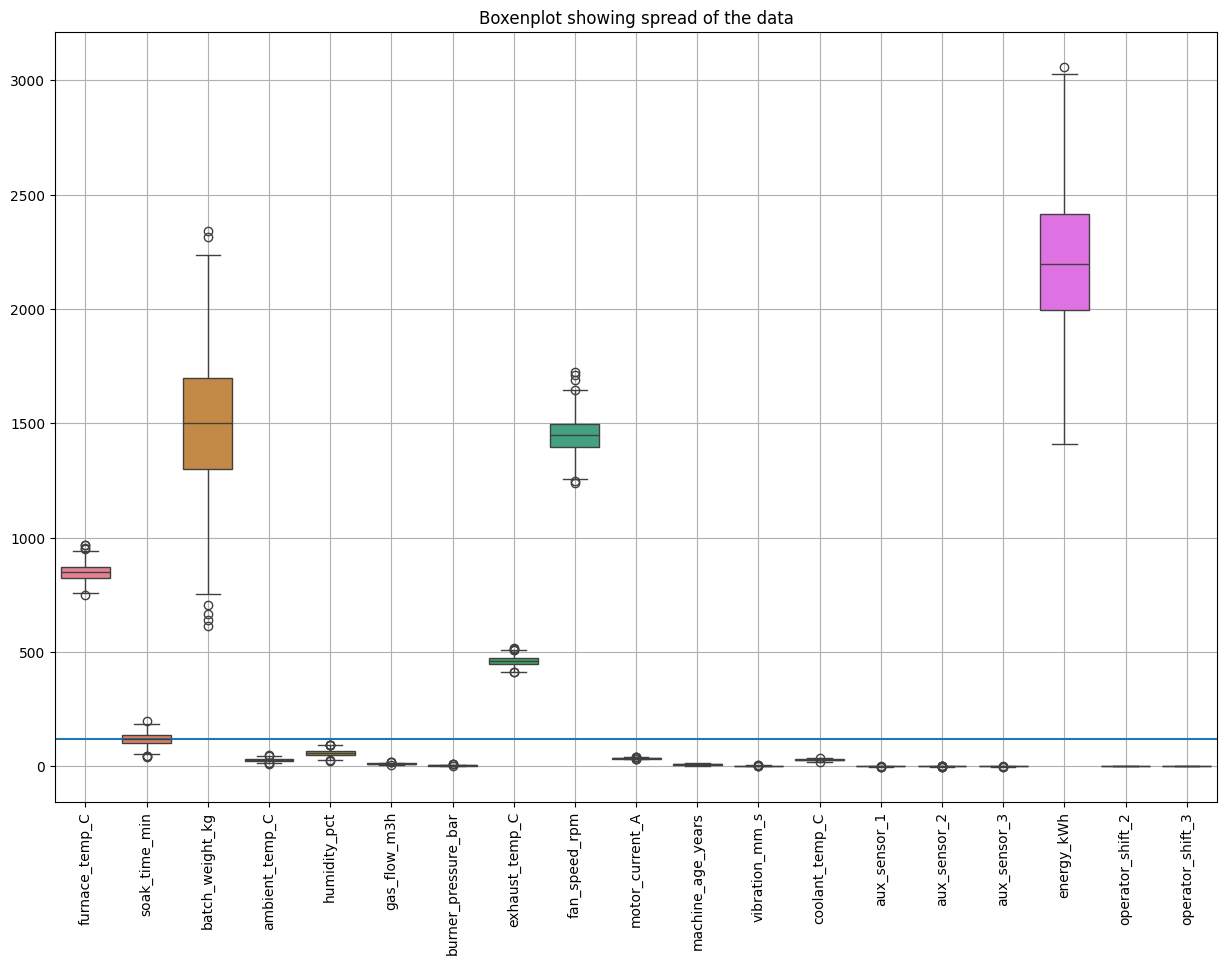

In [47]:
plt.figure (figsize = (15,10))
sns.boxplot(df)
plt.axhline(120)
plt.xticks(rotation = 90)
plt.title('Boxenplot showing spread of the data')
plt.grid()
plt.show()

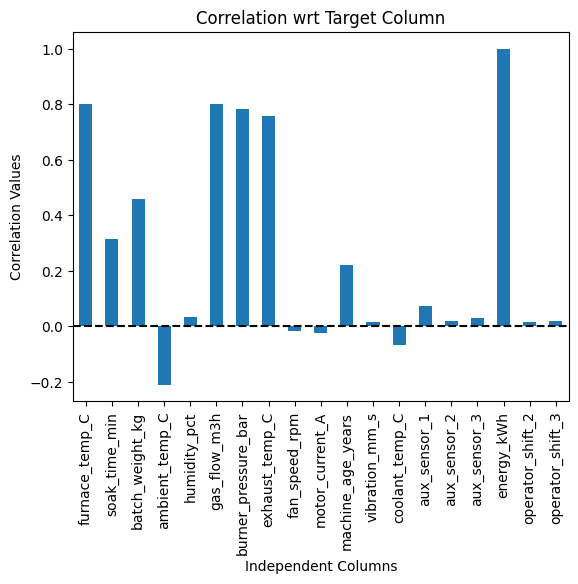

In [48]:
df.corr()['energy_kWh'].plot(kind = 'bar')
plt.axhline(0, linestyle = '--', color = 'black') #horizontal line
plt.title('Correlation wrt Target Column')
plt.ylabel('Correlation Values')
plt.xlabel('Independent Columns')
plt.show()

Text(0.5, 1.0, 'Heatmap showing Correlation w.r.t. Target Column')

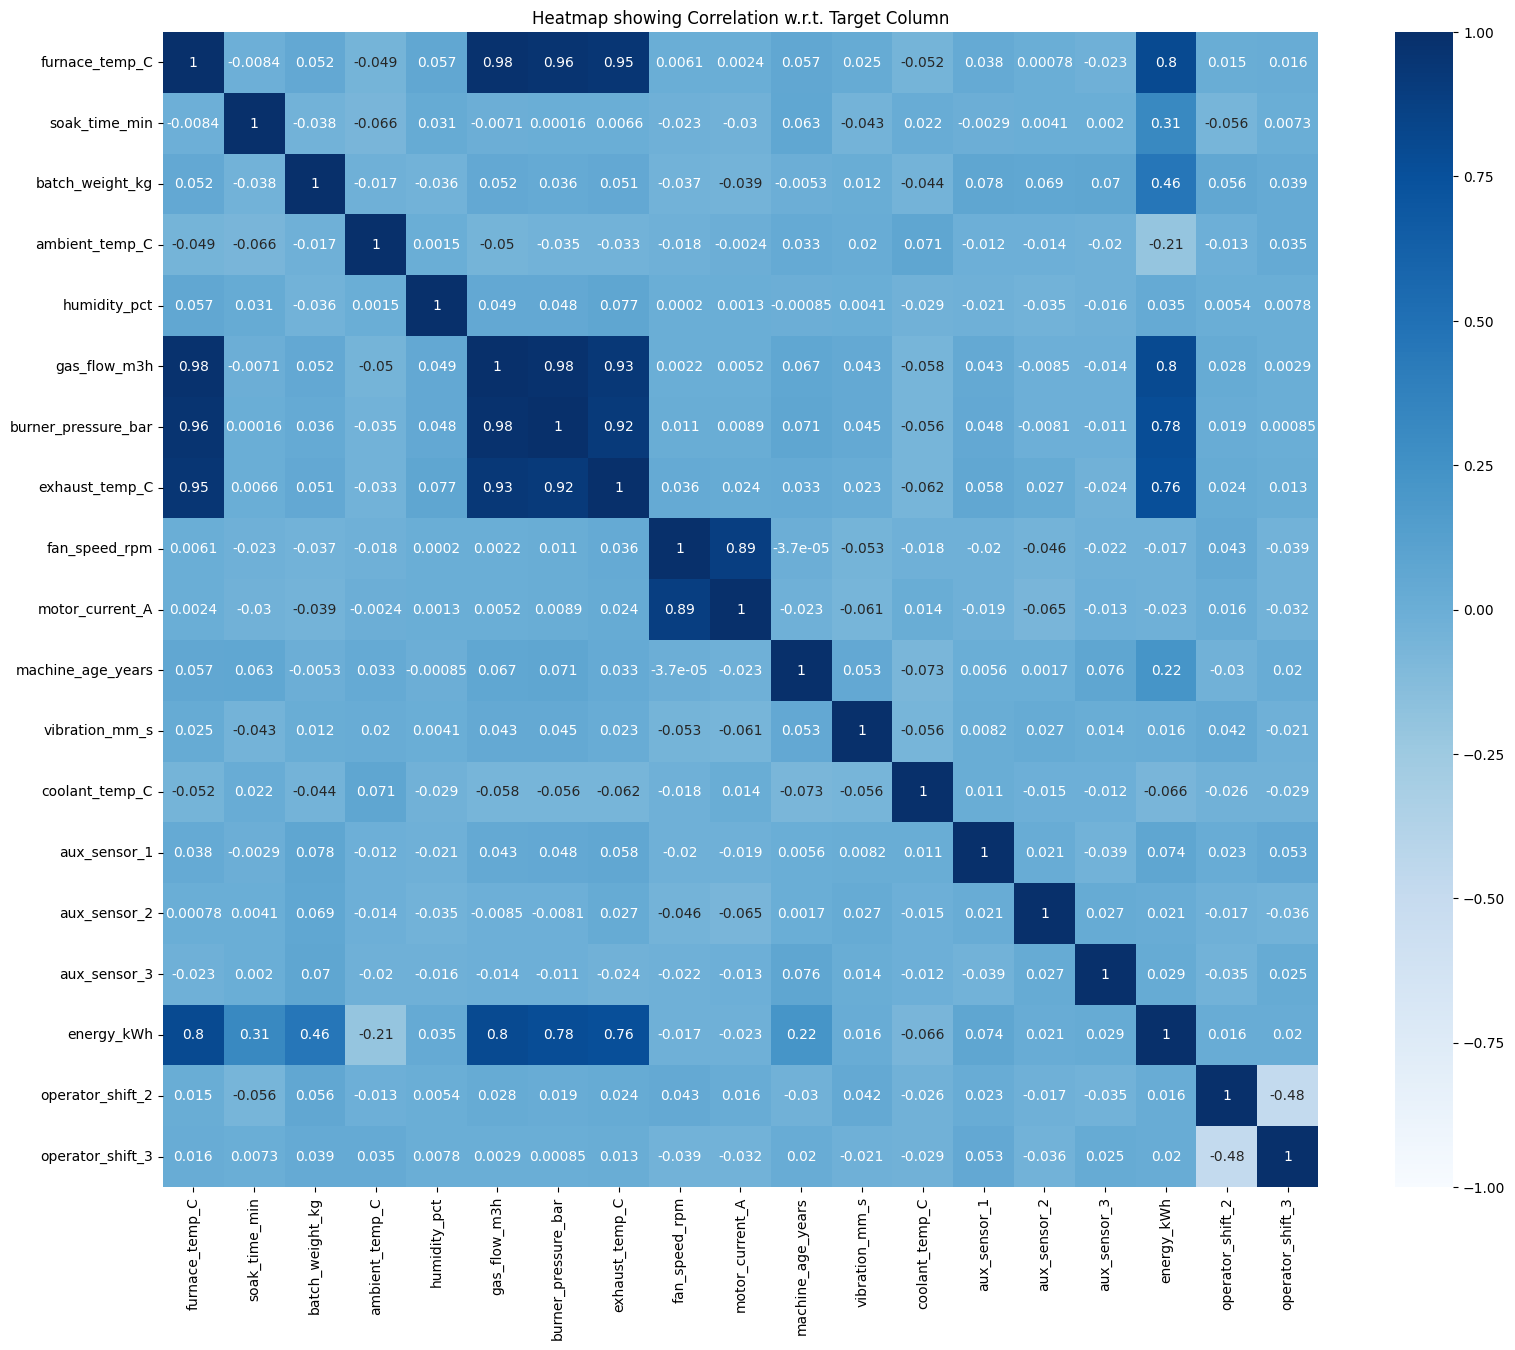

In [49]:
#last col of heatmap must be TARGET COLUMN
plt.figure(figsize=(20, 15))
sns.heatmap(df.corr(), cbar=True, square=True, annot=True, center = 0, vmax = 1, vmin= -1, cmap='Blues')

plt.title('Heatmap showing Correlation w.r.t. Target Column')

In [50]:
df.corr(numeric_only=True)

,furnace_temp_C,soak_time_min,batch_weight_kg,ambient_temp_C,humidity_pct,gas_flow_m3h,burner_pressure_bar,exhaust_temp_C,fan_speed_rpm,motor_current_A,machine_age_years,vibration_mm_s,coolant_temp_C,aux_sensor_1,aux_sensor_2,aux_sensor_3,energy_kWh,operator_shift_2,operator_shift_3
furnace_temp_C,1.000000,-0.008422,0.051663,-0.048661,0.057379,0.983168,0.964867,0.945958,0.006089,0.002444,0.056562,0.024720,-0.051763,0.037916,0.000777,-0.022962,0.801766,0.015189,0.015790
soak_time_min,-0.008422,1.000000,-0.037901,-0.065826,0.030961,-0.007095,0.000157,0.006595,-0.023274,-0.030110,0.062640,-0.043292,0.021858,-0.002884,0.004097,0.001988,0.314612,-0.056062,0.007296
batch_weight_kg,0.051663,-0.037901,1.000000,-0.017185,-0.035729,0.052454,0.035931,0.050601,-0.037451,-0.039231,-0.005250,0.011745,-0.044186,0.077921,0.068927,0.070373,0.457418,0.056375,0.038887
ambient_temp_C,-0.048661,-0.065826,-0.017185,1.000000,0.001546,-0.050039,-0.034735,-0.032546,-0.018262,-0.002374,0.032689,0.020078,0.071291,-0.012021,-0.014082,-0.019934,-0.209452,-0.013224,0.034683
humidity_pct,0.057379,0.030961,-0.035729,0.001546,1.000000,0.048812,0.047802,0.076851,0.000196,0.001259,-0.000851,0.004081,-0.029001,-0.021454,-0.035210,-0.015958,0.034575,0.005365,0.007773
gas_flow_m3h,0.983168,-0.007095,0.052454,-0.050039,0.048812,1.000000,0.982890,0.934894,0.002203,0.005209,0.067148,0.043097,-0.058144,0.042881,-0.008522,-0.013834,0.799404,0.028146,0.002868
burner_pressure_bar,0.964867,0.000157,0.035931,-0.034735,0.047802,0.982890,1.000000,0.916067,0.011069,0.008876,0.070770,0.045315,-0.055895,0.048346,-0.008078,-0.011027,0.781192,0.018756,0.000850
exhaust_temp_C,0.945958,0.006595,0.050601,-0.032546,0.076851,0.934894,0.916067,1.000000,0.036197,0.023991,0.033095,0.023100,-0.062038,0.057691,0.026810,-0.023657,0.758534,0.023689,0.013360
fan_speed_rpm,0.006089,-0.023274,-0.037451,-0.018262,0.000196,0.002203,0.011069,0.036197,1.000000,0.887657,-0.000037,-0.052758,-0.017747,-0.019529,-0.046119,-0.022483,-0.017398,0.042954,-0.038808
motor_current_A,0.002444,-0.030110,-0.039231,-0.002374,0.001259,0.005209,0.008876,0.023991,0.887657,1.000000,-0.022600,-0.061328,0.014141,-0.018931,-0.064609,-0.012725,-0.023378,0.016058,-0.032419


In [51]:
df.skew(numeric_only=True)


,0
furnace_temp_C,0.093710
soak_time_min,-0.128168
batch_weight_kg,-0.079270
ambient_temp_C,-0.024507
humidity_pct,-0.021038
gas_flow_m3h,0.041188
burner_pressure_bar,0.035445
exhaust_temp_C,0.095952
fan_speed_rpm,0.165634
motor_current_A,-0.016320


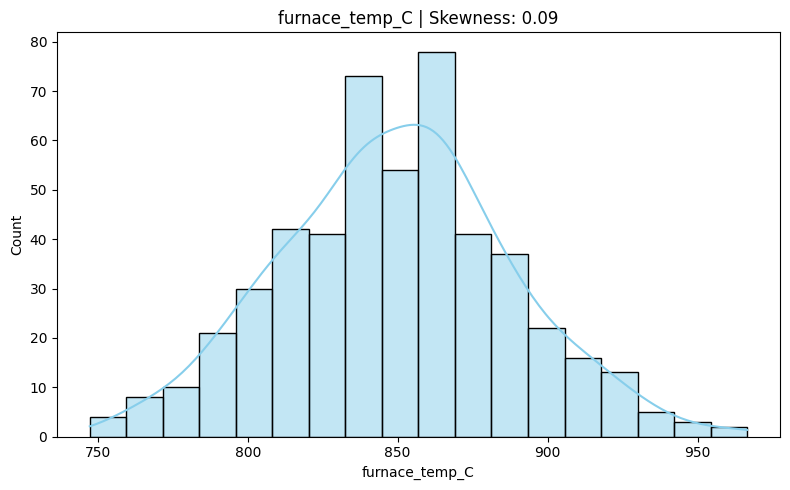

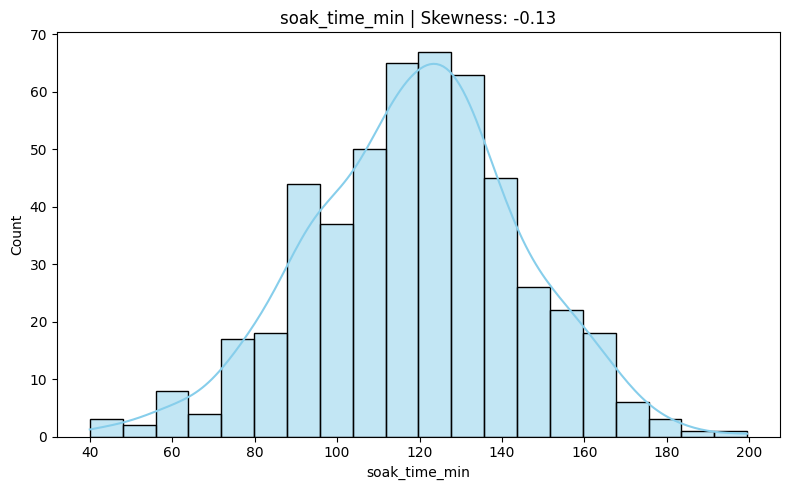

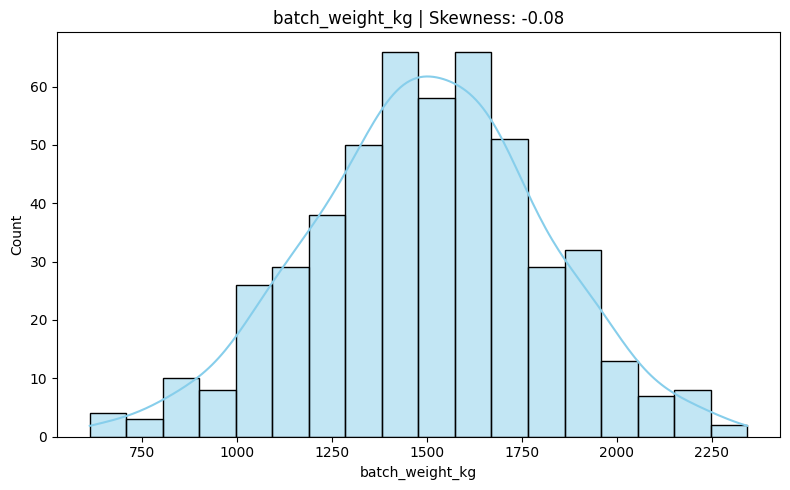

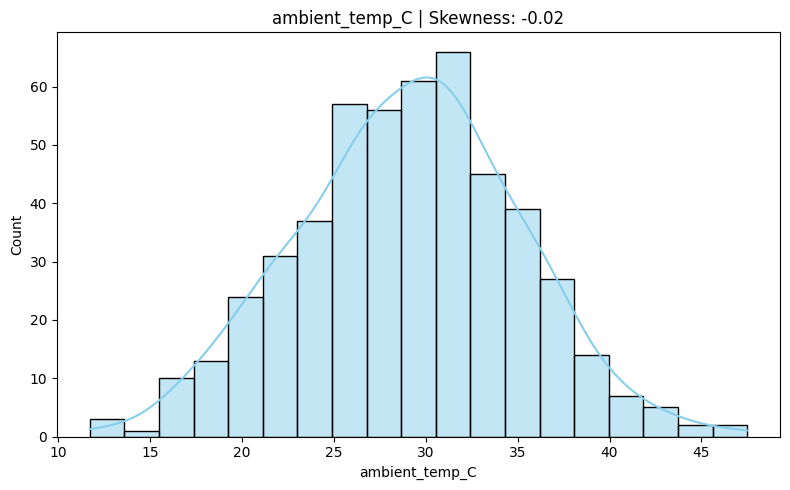

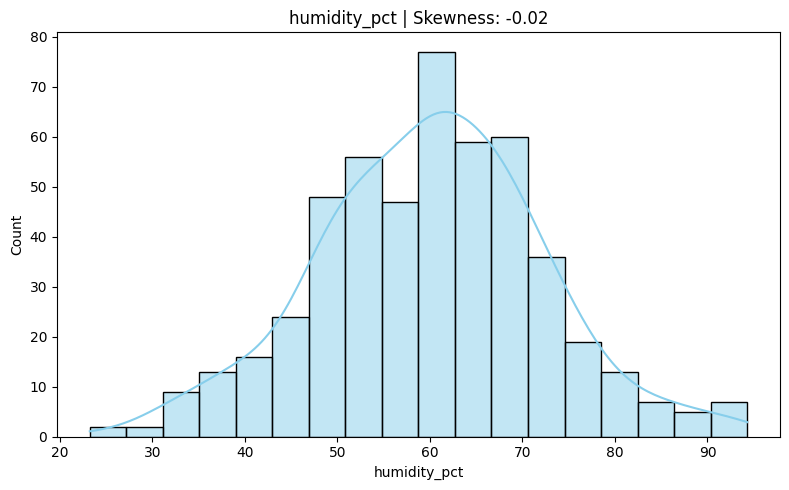

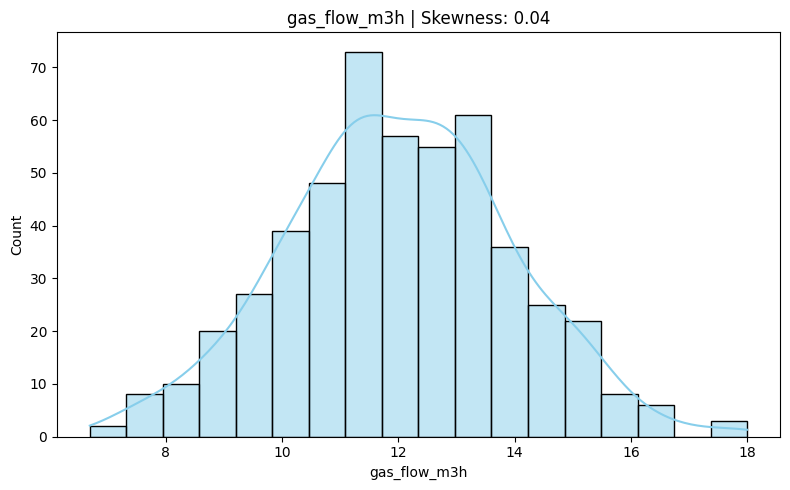

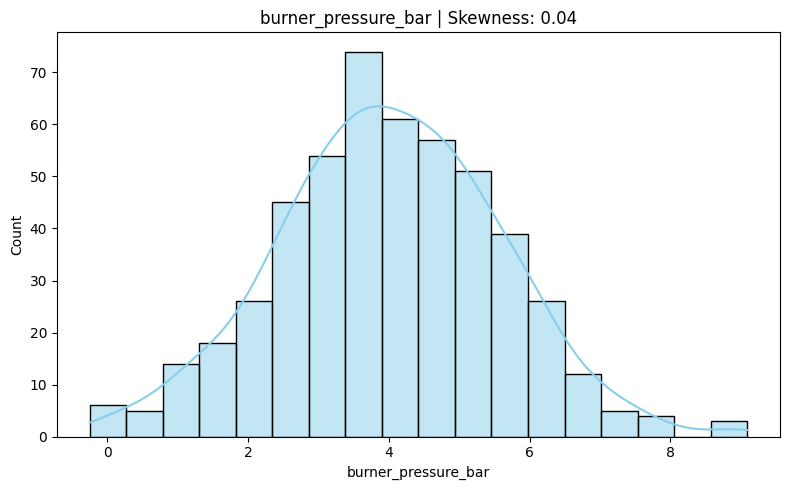

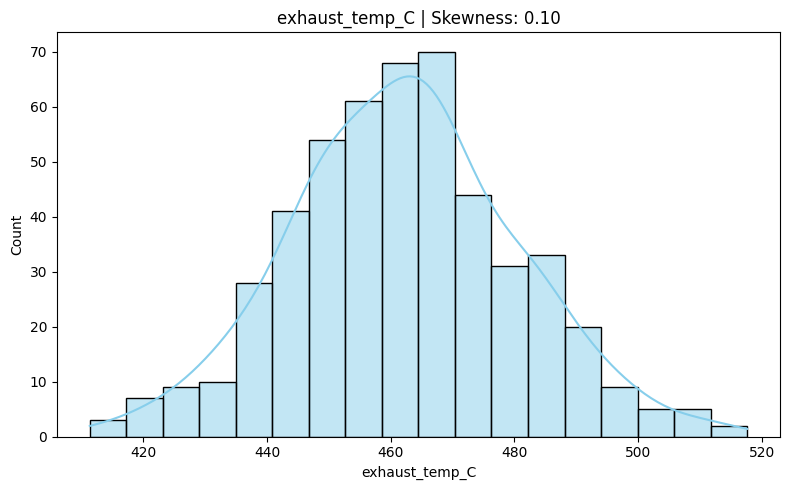

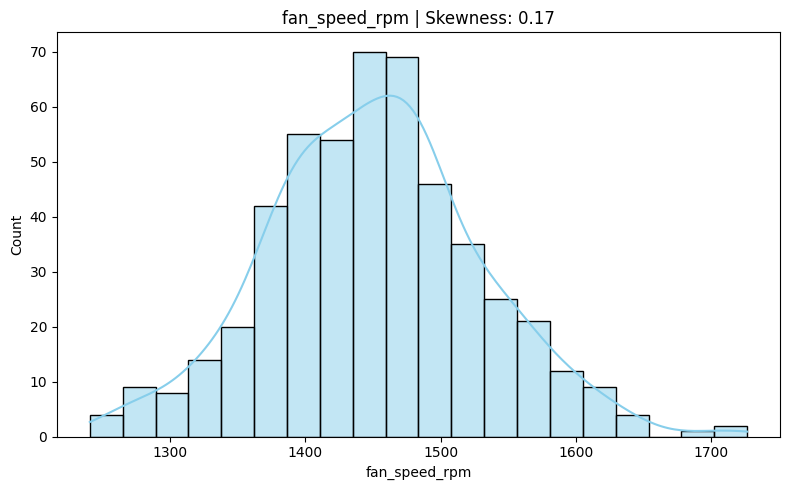

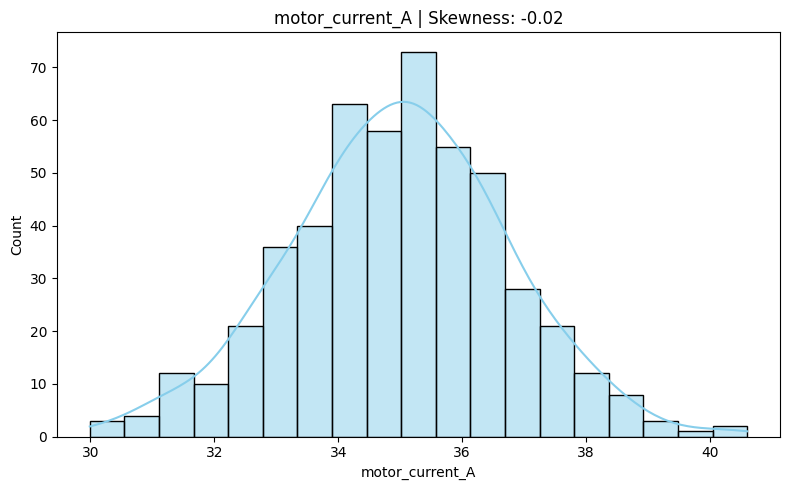

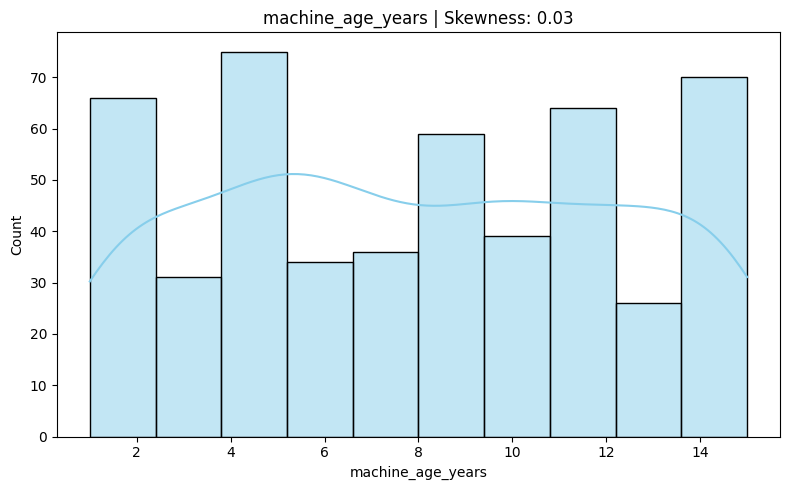

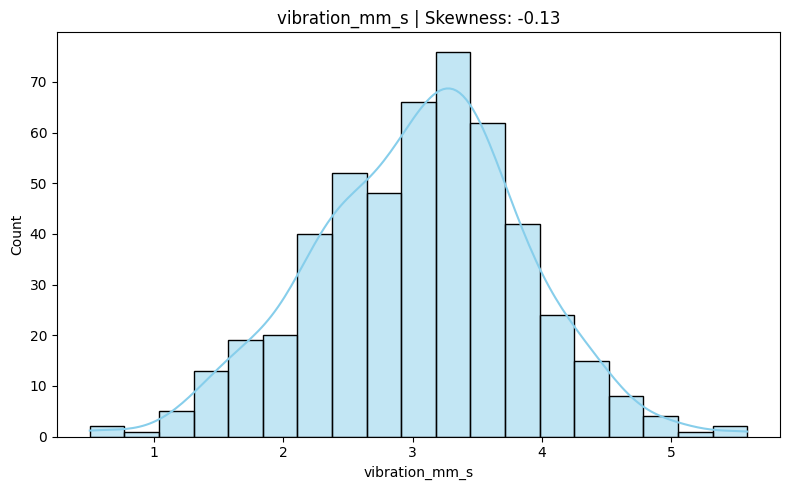

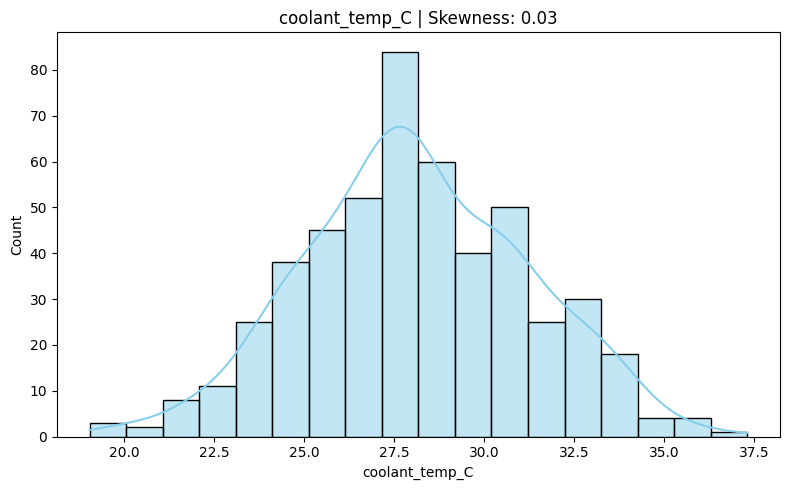

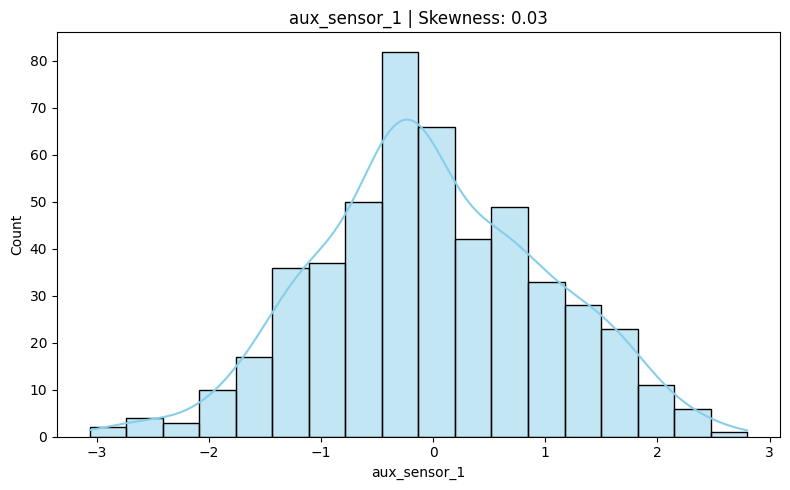

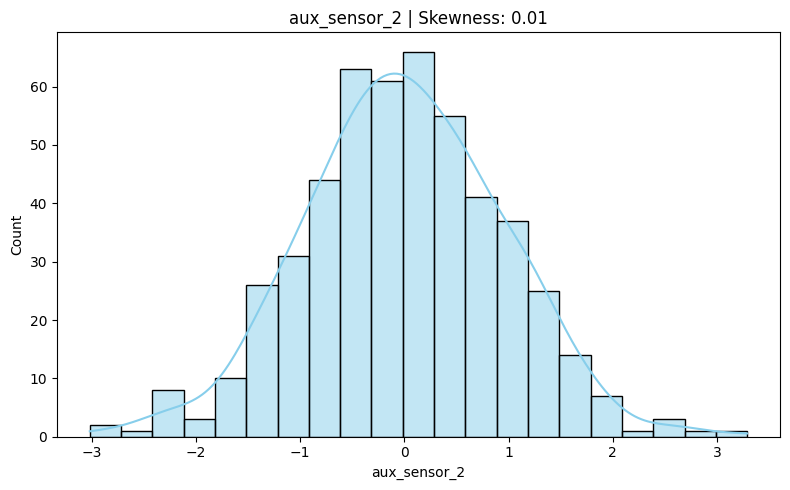

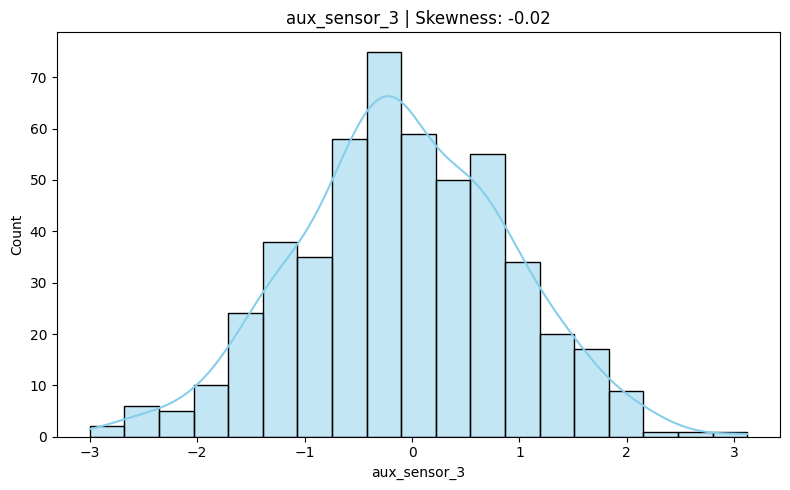

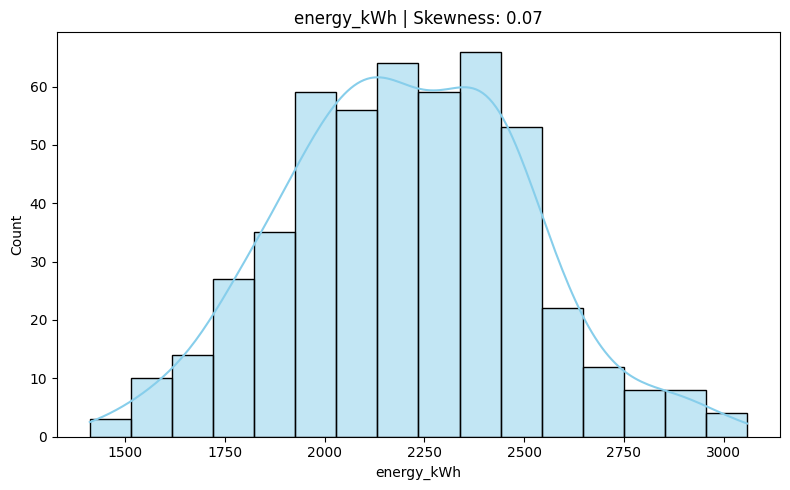

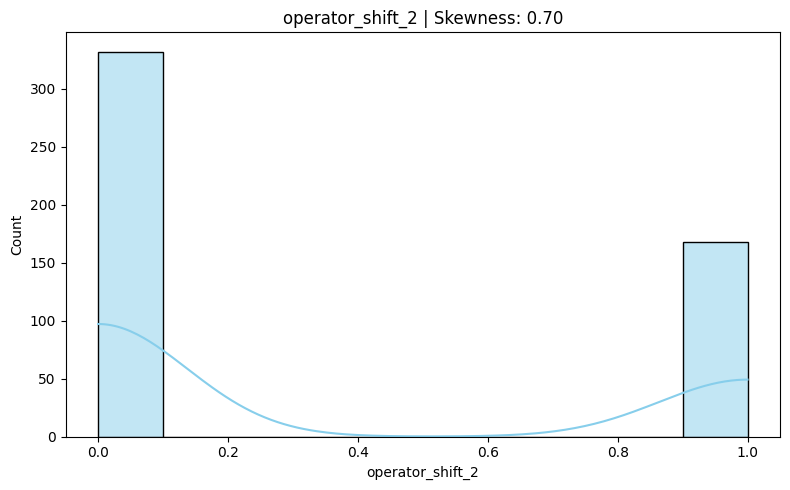

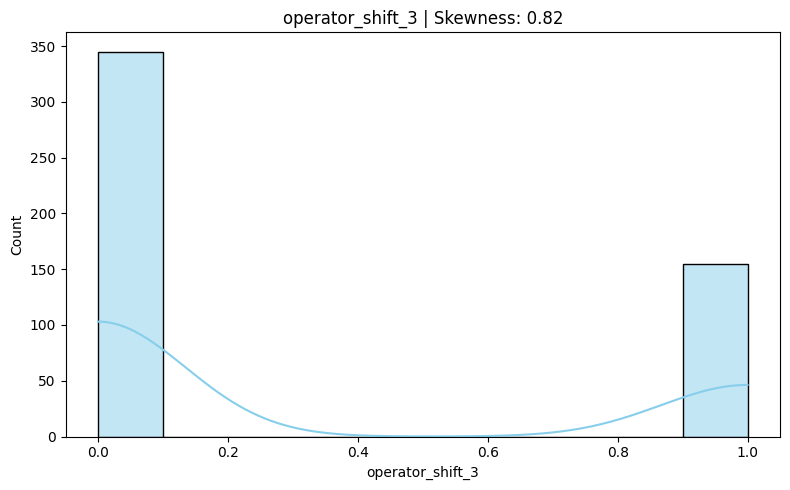

In [62]:
for col in df:
  col_skew = df[col].skew()

  plt.figure(figsize=(8, 5))
  sns.histplot(df[col], kde=True, color="skyblue")
  plt.title(f"{col} | Skewness: {col_skew:.2f}")
  plt.xlabel(col)
  plt.ylabel("Count")
  plt.tight_layout()
  plt.show()

<Axes: xlabel='ambient_temp_C', ylabel='Count'>

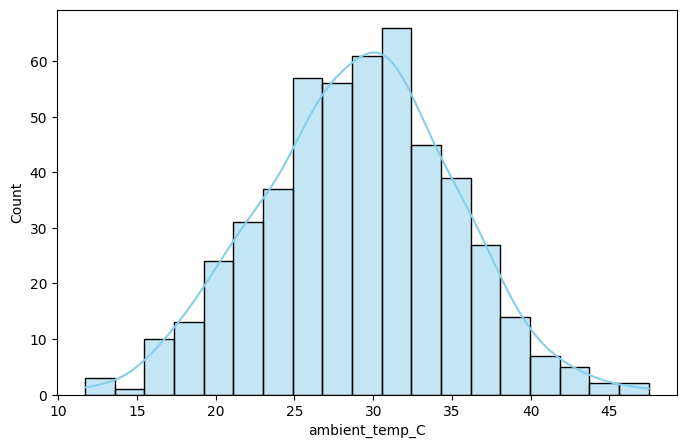

In [55]:
ambient_temp_C_skew = df['ambient_temp_C'].skew()
plt.figure(figsize=(8, 5))
sns.histplot(df['ambient_temp_C'], kde=True, color='skyblue')

In [56]:
#Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

RF = RandomForestRegressor().fit(xtrain,ytrain)
y_pred_RF = RF.predict(xtest)

print('The Model Accuracy for Decision Tree Regressor', r2_score(ytest,y_pred_RF))

The Model Accuracy for Decision Tree Regressor 0.8529924048088151


In [57]:
!pip install xgboost

In [58]:
import xgboost as xg

xgb = xg.XGBRegressor().fit(xtrain,ytrain)
y_pred_xgb = xgb.predict(xtest)

print('Model Accuracy for XGBoost Regressor', r2_score(ytest,y_pred_xgb))

Model Accuracy for XGBoost Regressor 0.8665427099763175


In [59]:
#Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

DT = DecisionTreeRegressor().fit(xtrain,ytrain)
y_pred_DT = DT.predict(xtest)

print('The Model Accuracy for Decision Tree Regressor', r2_score(ytest,y_pred_DT))

The Model Accuracy for Decision Tree Regressor 0.653618420804073


In [60]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_squared_error

mae = mean_absolute_error(ytest, ypred)
mse = mean_squared_error(ytest,ypred)
rmse = root_mean_squared_error(ytest,ypred)
r2_score = r2_score(ytest,ypred)

print("MAE",mae)
print("MSE",mse)
print("uRMSE",rmse)
print("R2 Score",r2_score*100)

MAE 36.59297647980802
MSE 2119.3987970479748
RMSE 46.036928623095335
R2 Score 97.85365944947957
